# 02 - Data preparation

This notebook prepares the raw CSV data for our two predictive models: forecasting regular-season points per game (to rank teams), and predicting if a team changes coach during the season. We focus on the NHL and use data up to 2009, where 2009 is our test season.

We load everything into DuckDB to make joining easier, check the data quality, and then build our modeling dataset.

## 1. Load data

Loading all the CSVs into an in-memory DuckDB database so we can use standard SQL to piece them together.

In [1]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 60)

ROOT = Path('.') if Path('hockey_development_data').exists() else Path('..')
raw_tables = {p.stem: pd.read_csv(p) for p in sorted((ROOT / 'hockey_development_data').glob('*.csv'))}

con = duckdb.connect()
for name, df in raw_tables.items():
    con.register(name, df)

print(f"Loaded {len(raw_tables)} tables.")
display(con.execute("SELECT lgID, count(*) AS n_seasons FROM Teams GROUP BY lgID ORDER BY n_seasons DESC").df())

Loaded 22 tables.


,lgID,n_seasons
0,NHL,1265
1,WHA,84
2,NHA,45
3,PCHA,41
4,WCHL,24


The NHL is by far the biggest league here, which confirms our choice to focus only on it.

## 2. Data quality

We check the six usual quality dimensions with one query each: completeness, uniqueness, validity, consistency, accuracy and timeliness. We only look at the NHL from 1967 on, since that's the data we'll model.

In [2]:
nhl = "lgID = 'NHL' AND year >= 1967"
checks = {
    'completeness: team-seasons missing special teams stats': f"SELECT count(*) FROM Teams WHERE {nhl} AND (PPG IS NULL OR PPC IS NULL)",
    'completeness: goalie rows missing shots against, 1967-1982': "SELECT count(*) FROM Goalies WHERE lgID = 'NHL' AND year BETWEEN 1967 AND 1982 AND SA IS NULL",
    'completeness: goalie rows missing shots against, 1983+': "SELECT count(*) FROM Goalies WHERE lgID = 'NHL' AND year >= 1983 AND SA IS NULL",
    'uniqueness: duplicate team-seasons': "SELECT count(*) - count(DISTINCT (year, lgID, tmID)) FROM Teams",
    'uniqueness: duplicate coach stints': "SELECT count(*) - count(DISTINCT (coachID, year, tmID, stint)) FROM Coaches",
    'uniqueness: duplicate player stints': "SELECT count(*) - count(DISTINCT (playerID, year, stint)) FROM Scoring",
    'validity: more power-play goals than chances': f"SELECT count(*) FROM Teams WHERE {nhl} AND (PPG > PPC OR PKG > PKC)",
    'validity: goalie with more goals against than shots': "SELECT count(*) FROM Goalies WHERE GA > SA",
    'consistency: W + L + T + OTL differs from games': f"SELECT count(*) FROM Teams WHERE {nhl} AND G <> W + L + coalesce(T, 0) + coalesce(OTL, 0)",
    'consistency: 2W + T + OTL differs from points': f"SELECT count(*) FROM Teams WHERE {nhl} AND Pts <> 2 * W + coalesce(T, 0) + coalesce(OTL, 0)",
    'accuracy: team goals differ from summed player goals': f"""SELECT count(*) FROM Teams t
        JOIN (SELECT year, lgID, tmID, sum(G) AS goals FROM Scoring GROUP BY ALL) s USING (year, lgID, tmID)
        WHERE t.{nhl} AND t.GF <> s.goals""",
    'accuracy: same, after adding shootout wins': f"""SELECT count(*) FROM Teams t
        JOIN (SELECT year, lgID, tmID, sum(G) AS goals FROM Scoring GROUP BY ALL) s USING (year, lgID, tmID)
        WHERE t.{nhl} AND t.GF <> s.goals + coalesce(t.SoW, 0)""",
}
quality = pd.DataFrame({'check': list(checks), 'rows': [con.execute(q).fetchall()[0][0] for q in checks.values()]})
display(quality)

print("Last season in each table:", {t: int(raw_tables[t]['year'].max()) for t in ['Teams', 'Scoring', 'Goalies', 'Coaches', 'SeriesPost']})

coaches = raw_tables['Coaches']
display(coaches[coaches['coachID'].isin(['gretzwa01c', 'tippeda01c']) & (coaches['year'] >= 2007)])

coaches_clean = coaches.copy()
fix_mask = (coaches_clean['coachID'] == 'gretzwa01c') & (coaches_clean['year'] == 2009) & (coaches_clean['tmID'] == 'PHO')
coaches_clean.loc[fix_mask, 'coachID'] = 'tippeda01c'

,check,rows
0,completeness: team-seasons missing special tea...,0
1,completeness: goalie rows missing shots agains...,783
2,completeness: goalie rows missing shots agains...,6
3,uniqueness: duplicate team-seasons,0
4,uniqueness: duplicate coach stints,0
5,uniqueness: duplicate player stints,0
6,validity: more power-play goals than chances,0
7,validity: goalie with more goals against than ...,0
8,consistency: W + L + T + OTL differs from games,0
9,consistency: 2W + T + OTL differs from points,0


Last season in each table: {'Teams': 2009, 'Scoring': 2009, 'Goalies': 2009, 'Coaches': 2009, 'SeriesPost': 2009}


,coachID,year,tmID,lgID,stint,notes,g,w,l,t,postg,postw,postl,postt
573,gretzwa01c,2007,PHO,NHL,1,NaN,82.0,38.0,37.0,7.0,NaN,NaN,NaN,NaN
574,gretzwa01c,2008,PHO,NHL,1,NaN,82.0,36.0,39.0,7.0,NaN,NaN,NaN,NaN
575,gretzwa01c,2009,PHO,NHL,1,NaN,82.0,50.0,25.0,7.0,7.0,3.0,4.0,0.0
1633,tippeda01c,2007,DAL,NHL,1,NaN,82.0,45.0,30.0,7.0,18.0,10.0,8.0,0.0
1634,tippeda01c,2008,DAL,NHL,1,NaN,82.0,36.0,35.0,11.0,NaN,NaN,NaN,NaN


**What we found:** Almost everything passes. There are no duplicates and no impossible values, and the games and points formulas hold for every team since 1967. Two things stood out:
- Goalie shots against are missing for 783 goalie rows before 1983 but only 6 after, so save percentage only exists from 1983 on.
- Team goals don't match the sum of player goals in 149 seasons, all from 2005 on. A shootout win counts as one extra goal for the team but not for any player. After adding shootout wins, every season matches, so in the next section we remove shootout goals from team goals.

All tables run until 2009, and everything we use is known before the next season starts. We skip the Hall of Fame table, since inductions happen years later.

We also found one wrong row while building the coach features: Wayne Gretzky is listed as Phoenix's coach in 2009, but Dave Tippett was hired a week before that season (his record above stops at Dallas 2008). We fix it in a copy and leave the raw file alone.

## 3. Build Team Profiles

Let's combine the different tables into a single profile for each team-season: the main `Teams` table plus home/road and monthly splits, playoff series, rosters (with ages from `Master`) and goalies. Team goals have the shootout goals removed (see section 2). Then we check that every row from the other tables actually finds its team.

In [3]:
con.execute("""
CREATE OR REPLACE TABLE profile AS
WITH team AS (
    SELECT year, lgID, tmID, franchID, G,
           GF - coalesce(SoW, 0) AS gf_play, GA - coalesce(SoL, 0) AS ga_play, 
           Pts / G AS ppg, PPG / PPC AS pp_pct, 1 - PKG / PKC AS pk_pct, PIM / G AS pim_pg, (SHF - SHA) / G AS shorthanded_net_pg
    FROM Teams WHERE lgID = 'NHL'),
splits AS (
    SELECT year, lgID, tmID,
           hW / (hW + hL + coalesce(hT, 0) + coalesce(hOTL, 0)) - rW / (rW + rL + coalesce(rT, 0) + coalesce(rOTL, 0)) AS home_edge,
           (coalesce(FebW, 0) + coalesce(MarW, 0) + coalesce(AprW, 0))
             / nullif(coalesce(FebW, 0) + coalesce(FebL, 0) + coalesce(FebT, 0) + coalesce(FebOL, 0)
                    + coalesce(MarW, 0) + coalesce(MarL, 0) + coalesce(MarT, 0) + coalesce(MarOL, 0)
                    + coalesce(AprW, 0) + coalesce(AprL, 0) + coalesce(AprT, 0) + coalesce(AprOL, 0), 0) AS late_win_pct,
           (hW + rW) / (hW + hL + coalesce(hT, 0) + coalesce(hOTL, 0) + rW + rL + coalesce(rT, 0) + coalesce(rOTL, 0)) AS season_win_pct
    FROM TeamSplits WHERE lgID = 'NHL'),
series AS (
    SELECT year, lgID, tmID, sum(won) AS playoff_series_won, 1 AS made_playoffs FROM (
        SELECT year, lgIDWinner AS lgID, tmIDWinner AS tmID, 1 AS won FROM SeriesPost
        UNION ALL SELECT year, lgIDLoser, tmIDLoser, 0 FROM SeriesPost) GROUP BY ALL),
skaters AS (
    SELECT s.year, s.lgID, s.tmID, s.playerID, s.GP, s.Pts, s.year - m.birthYear AS age
    FROM Scoring s LEFT JOIN Master m USING (playerID) WHERE s.lgID = 'NHL'),
roster AS (
    SELECT year, lgID, tmID, count(DISTINCT playerID) AS players_used,
           sum(GP * age) / sum(GP) AS roster_age
    FROM skaters GROUP BY ALL),
goalies AS (
    SELECT year, lgID, tmID,
           CASE WHEN count(SA) = count(*) THEN 1 - sum(GA) / sum(SA) END AS save_pct,
           max(Min) / nullif(sum(Min), 0) AS starter_minutes_share
    FROM Goalies WHERE lgID = 'NHL' GROUP BY ALL)
SELECT team.*, gf_play / G AS gf_pg, ga_play / G AS ga_pg, (gf_play - ga_play) / G AS gd_pg,
       gf_play ^ 2 / (gf_play ^ 2 + ga_play ^ 2) AS pythag,
       splits.home_edge, splits.late_win_pct - splits.season_win_pct AS late_form,
       coalesce(series.playoff_series_won, 0) AS playoff_series_won, coalesce(series.made_playoffs, 0) AS made_playoffs,
       roster.players_used, roster.roster_age,
       goalies.save_pct, goalies.starter_minutes_share
FROM team
LEFT JOIN splits USING (year, lgID, tmID) 
LEFT JOIN series USING (year, lgID, tmID)
LEFT JOIN roster USING (year, lgID, tmID) 
LEFT JOIN goalies USING (year, lgID, tmID)
""")

# Add 'luck' metric: points earned compared to expected points from goal differential
con.execute("ALTER TABLE profile ADD COLUMN luck DOUBLE")
con.execute("UPDATE profile SET luck = ppg / 2 - pythag")

profile = con.execute('SELECT * FROM profile ORDER BY year, tmID').df()
print(f'Profile rows: {len(profile)} | columns: {profile.shape[1]}')

display(profile[profile['year'] == 2008].sort_values('ppg', ascending=False).head(5).round(3))

match = con.execute("""
    SELECT 'Scoring' AS source, avg((p.tmID IS NOT NULL)::INT) AS match_rate FROM Scoring s LEFT JOIN profile p USING (year, lgID, tmID) WHERE s.lgID = 'NHL'
    UNION ALL SELECT 'Goalies', avg((p.tmID IS NOT NULL)::INT) FROM Goalies s LEFT JOIN profile p USING (year, lgID, tmID) WHERE s.lgID = 'NHL'
    UNION ALL SELECT 'Coaches', avg((p.tmID IS NOT NULL)::INT) FROM Coaches s LEFT JOIN profile p USING (year, lgID, tmID) WHERE s.lgID = 'NHL'
    UNION ALL SELECT 'TeamSplits', avg((p.tmID IS NOT NULL)::INT) FROM TeamSplits s LEFT JOIN profile p USING (year, lgID, tmID) WHERE s.lgID = 'NHL'
    UNION ALL SELECT 'SeriesPost', avg((p.tmID IS NOT NULL)::INT) FROM SeriesPost s
        LEFT JOIN profile p ON s.year = p.year AND s.lgIDWinner = p.lgID AND s.tmIDWinner = p.tmID WHERE s.lgIDWinner = 'NHL'
    UNION ALL SELECT 'Scoring -> Master', avg((m.playerID IS NOT NULL)::INT) FROM Scoring s LEFT JOIN Master m USING (playerID) WHERE s.lgID = 'NHL'
""").df()
display(match)

display(con.execute("""
    SELECT w.franchID, w.tmID AS wha_team, n.tmID AS nhl_team, n.name
    FROM Teams w JOIN Teams n ON w.franchID = n.franchID AND n.lgID = 'NHL' AND n.year = 1979
    WHERE w.lgID = 'WHA' AND w.year = 1978
""").df())

Profile rows: 1265 | columns: 25


,year,lgID,tmID,franchID,G,gf_play,ga_play,ppg,pp_pct,pk_pct,pim_pg,shorthanded_net_pg,gf_pg,ga_pg,gd_pg,pythag,home_edge,late_form,playoff_series_won,made_playoffs,players_used,roster_age,save_pct,starter_minutes_share,luck
1229,2008,NHL,SJS,SJS,82,251.0,199.0,1.427,0.242,0.833,12.841,0.012,3.061,2.427,0.634,0.614,0.268,-0.146,0.0,1,31,28.012,0.912,0.741,0.099
1207,2008,NHL,BOS,BOS,82,270.0,190.0,1.415,0.236,0.824,12.537,0.012,3.293,2.317,0.976,0.669,0.122,-0.115,1.0,1,32,27.430,0.927,0.657,0.039
1215,2008,NHL,DET,DET,82,289.0,240.0,1.366,0.255,0.783,10.049,0.024,3.524,2.927,0.598,0.592,0.073,-0.016,3.0,1,29,30.508,0.896,0.536,0.091
1234,2008,NHL,WAS,WAS,82,268.0,240.0,1.317,0.252,0.806,12.695,-0.049,3.268,2.927,0.341,0.555,0.195,-0.016,1.0,1,39,27.259,0.903,0.662,0.104
1222,2008,NHL,NJD,NJD,82,238.0,207.0,1.293,0.189,0.799,12.902,0.098,2.902,2.524,0.378,0.569,0.122,-0.028,0.0,1,32,29.856,0.917,0.475,0.077


,source,match_rate
0,Scoring,1.0
1,Goalies,1.0
2,Coaches,1.0
3,TeamSplits,1.0
4,SeriesPost,1.0
5,Scoring -> Master,1.0


,franchID,wha_team,nhl_team,name
0,EDM,EDO,EDM,Edmonton Oilers
1,CAR,NEW,HAR,Hartford Whalers
2,COL,QUN,QUE,Quebec Nordiques
3,PHO,WIJ,WIN,Winnipeg Jets


**What we found:** Every NHL row from Scoring, Goalies, Coaches, TeamSplits and SeriesPost found its team-season, and every player matched a record in `Master` (match rate 1.0 everywhere). We end up with 1,265 team-seasons and 25 columns. In the 2008 preview, San Jose had the best points per game and Detroit won 3 playoff series (they made the final).

Four teams joined from the WHA in 1979 and kept the same franchise ID. We don't use their WHA seasons as a "previous season" since it was a different league, so they count as new teams in 1979.

## 4. Feature engineering and targets

Next, we line up our targets (points per game, ranks, and whether the team changed coach during the season) with the data we'll use to predict them.

We join each season to the profile of the team's *previous* completed season. We also add some facts about the coach on opening day, which are known before the season starts: is he new, how many seasons has he been with the team, what's his career record, and did the team change coach last season.

One quirk: the 2004 season was canceled due to a lockout, so the "previous" season for 2005 is actually 2003. We keep track of this gap in `prev_gap`.

In [4]:
seasons = sorted(profile['year'].unique())
season_map = pd.DataFrame({'year': seasons[1:], 'prev_year': seasons[:-1]})
season_map['prev_gap'] = season_map['year'] - season_map['prev_year']

print('Seasons with a gap longer than 1 year:')
display(season_map[season_map['prev_gap'] > 1])

coaches = coaches_clean[coaches_clean['lgID'] == 'NHL'].merge(
    profile[['year', 'lgID', 'tmID', 'franchID']], on=['year', 'lgID', 'tmID'])
coach_season = (coaches.sort_values('stint').groupby(['year', 'franchID'])
                .agg(start_coach=('coachID', 'first'), end_coach=('coachID', 'last'), stints=('stint', 'nunique'))
                .reset_index())
coach_season['coach_change'] = (coach_season['stints'] > 1).astype(int)

# Opening-day coach facts: all known the day before the season starts
coach_season = coach_season.merge(season_map, on='year', how='left')
prev_coach = coach_season[['year', 'franchID', 'start_coach', 'end_coach', 'coach_change']].rename(columns={
    'year': 'prev_year', 'start_coach': 'prev_start_coach', 'end_coach': 'prev_end_coach', 'coach_change': 'prev_coach_change'})
coach_season = coach_season.merge(prev_coach, on=['prev_year', 'franchID'], how='left')
coach_season['coach_new'] = (coach_season['start_coach'] != coach_season['prev_end_coach']).astype(int).where(
    coach_season['prev_end_coach'].notna())

tenure = {}
for r in coach_season.sort_values('year').itertuples():
    if r.coach_new != 0:
        tenure[(r.year, r.franchID)] = 0
    elif r.prev_start_coach == r.start_coach:
        tenure[(r.year, r.franchID)] = tenure[(r.prev_year, r.franchID)] + 1
    else:
        tenure[(r.year, r.franchID)] = 1
coach_season['coach_tenure'] = [tenure[k] for k in zip(coach_season['year'], coach_season['franchID'])]

# Career record before season t
career = (coaches_clean.groupby(['coachID', 'year'])[['g', 'w', 't']].sum()
          .groupby(level=0).cumsum().groupby(level=0).shift().fillna(0).reset_index())
career['coach_career_pct'] = ((2 * career['w'] + career['t']) / (2 * career['g'])).where(career['g'] > 0)
career = career.rename(columns={'coachID': 'start_coach', 'g': 'coach_career_games'})
coach_season = coach_season.merge(career[['start_coach', 'year', 'coach_career_games', 'coach_career_pct']],
                                  on=['start_coach', 'year'], how='left')

COACH_FEATURES = ['coach_new', 'coach_tenure', 'coach_career_games', 'coach_career_pct', 'prev_coach_change']
PROFILE_FEATURES = ['ppg', 'gf_pg', 'ga_pg', 'gd_pg', 'pythag', 'luck', 'pp_pct', 'pk_pct', 'pim_pg', 'shorthanded_net_pg',
                    'home_edge', 'late_form', 'playoff_series_won', 'made_playoffs', 'players_used', 'roster_age',
                    'save_pct', 'starter_minutes_share']

targets = profile[['year', 'lgID', 'tmID', 'franchID', 'G', 'ppg']].merge(
    raw_tables['Teams'][['year', 'lgID', 'tmID', 'name', 'confID', 'divID', 'Pts', 'rank']], on=['year', 'lgID', 'tmID'])
targets = targets.rename(columns={'G': 'games', 'ppg': 'target_ppg', 'Pts': 'target_points', 'rank': 'target_rank_division'})
targets['target_rank_league'] = targets.groupby('year')['target_points'].rank(ascending=False, method='min').astype(int)
targets = targets.merge(coach_season[['year', 'franchID', 'coach_change'] + COACH_FEATURES], on=['year', 'franchID'], how='left')
targets = targets.rename(columns={'coach_change': 'target_coach_change'})

prev = profile[['year', 'franchID'] + PROFILE_FEATURES].copy()
prev.columns = ['prev_' + col if col not in ['year', 'franchID'] else col for col in prev.columns]
prev = prev.rename(columns={'year': 'prev_year'})

frame = targets.merge(season_map, on='year', how='left')
frame = frame.merge(prev, on=['prev_year', 'franchID'], how='left')
frame['has_prev'] = frame['prev_ppg'].notna().astype(int)

print(f'\nAssembled rows: {len(frame)}')
print(f'Rows with prior-season profile: {frame["has_prev"].sum()}')
display(frame[frame['year'] == 2009][['year', 'tmID', 'prev_ppg', 'coach_new', 'coach_tenure', 'coach_career_pct',
                                     'target_rank_league', 'target_coach_change']].head())

Seasons with a gap longer than 1 year:


,year,prev_year,prev_gap
86,2005,2003,2



Assembled rows: 1265
Rows with prior-season profile: 1228


,year,tmID,prev_ppg,coach_new,coach_tenure,coach_career_pct,target_rank_league,target_coach_change
1235,2009,AND,1.109756,0.0,4,0.611280,17,0
1236,2009,ATL,0.926829,0.0,1,0.463415,23,0
1237,2009,BOS,1.414634,0.0,2,0.587065,14,0
1238,2009,BUF,1.109756,0.0,11,0.547672,10,0
1239,2009,CAL,1.195122,1.0,0,0.625000,15,0


**What we found:** Only 2005 has a gap (it uses 2003). 1,228 of the 1,265 team-seasons have a previous season; the other 37 are brand new teams. The coach features look right: in 2009 Buffalo's coach (Lindy Ruff) had 11 previous seasons with the team, and Calgary started with a new coach.

## 5. Standardizing across eras

Hockey has changed a lot since 1967. Scoring rates go up and down, and rules change (like getting a point for overtime losses).

To make a team from 1975 comparable to a team from 2007, we convert their stats into z-scores *relative to their own season*. We also group coach tenure into bands and look at how coach changes depend on tenure and last season's standing.

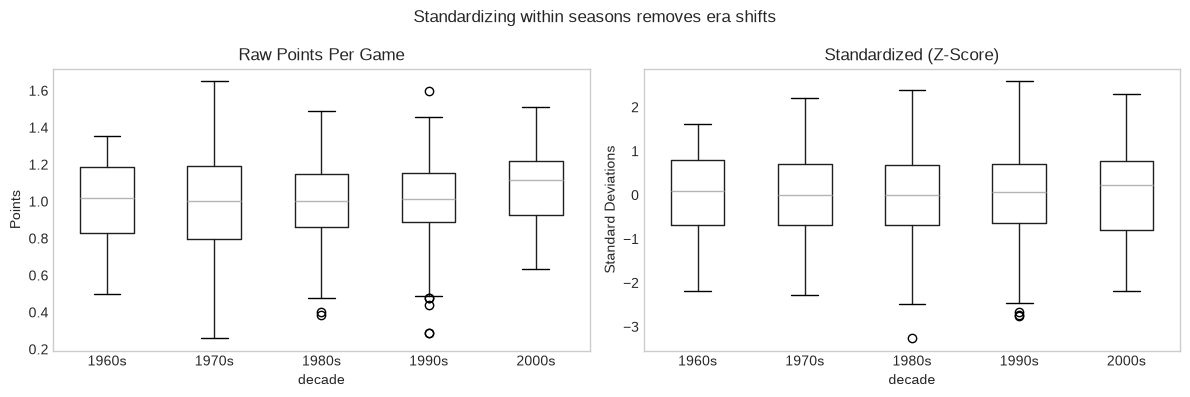

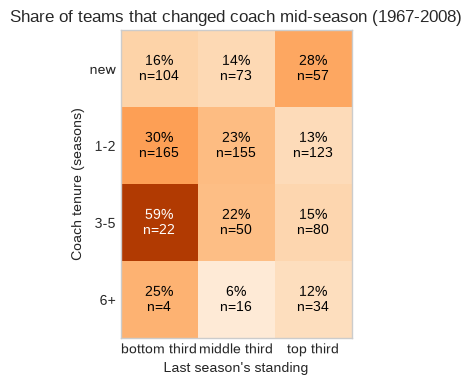

In [5]:
Z_FEATURES = [f for f in PROFILE_FEATURES if f != 'made_playoffs']
for feature in Z_FEATURES:
    by_season = frame.groupby('prev_year')[f'prev_{feature}']
    frame[f'prev_{feature}_z'] = (frame[f'prev_{feature}'] - by_season.transform('mean')) / by_season.transform('std')

frame['target_ppg_z'] = frame.groupby('year')['target_ppg'].transform(lambda x: (x - x.mean()) / x.std())

dev = frame[frame['year'].between(1967, 2008)].copy()
dev['decade'] = (dev['prev_year'] // 10 * 10).astype('Int64').astype(str) + 's'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
dev.boxplot(column='prev_ppg', by='decade', ax=axes[0], grid=False)
axes[0].set_title('Raw Points Per Game')
axes[0].set_ylabel('Points')
dev.boxplot(column='prev_ppg_z', by='decade', ax=axes[1], grid=False)
axes[1].set_title('Standardized (Z-Score)')
axes[1].set_ylabel('Standard Deviations')
plt.suptitle('Standardizing within seasons removes era shifts')
plt.tight_layout()
plt.show()

dev['tenure'] = pd.cut(dev['coach_tenure'], [-1, 0, 2, 5, 100], labels=['new', '1-2', '3-5', '6+'])
dev['standing'] = pd.qcut(dev['prev_ppg_z'], 3, labels=['bottom third', 'middle third', 'top third'])
rate = dev.pivot_table(index='tenure', columns='standing', values='target_coach_change', aggfunc='mean', observed=False)
count = dev.pivot_table(index='tenure', columns='standing', values='target_coach_change', aggfunc='size', observed=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.imshow(rate, cmap='Oranges', vmin=0, vmax=0.7)
ax.set_xticks(range(3), rate.columns)
ax.set_yticks(range(4), rate.index)
ax.grid(False)
for i in range(4):
    for j in range(3):
        ax.text(j, i, f'{rate.iat[i, j]:.0%}\nn={count.iat[i, j]}', ha='center', va='center', color='white' if rate.iat[i, j] > 0.4 else 'black')
ax.set_xlabel("Last season's standing")
ax.set_ylabel('Coach tenure (seasons)')
ax.set_title('Share of teams that changed coach mid-season (1967-2008)')
plt.show()

**What we found:** On the left, raw points per game jump in the 2000s because of the extra point for overtime and shootout losses. On the right, every decade is centered around 0, so the eras are comparable.

The heatmap shows that coach changes depend on both tenure and last season's results. Coaches in their 3rd-5th season with a bottom-third team were replaced most often (59%), while long-serving coaches with decent teams almost never were (6-12%). Oddly, new coaches of top teams also changed fairly often (28%). Some cells are small (only 4 teams with a 6+ season coach and a bottom-third finish), so this is a hint rather than a rule, but it suggests models that handle interactions, like trees, could help with coach changes.

## 6. Outliers

We look for outliers in three ways: values more than 3 SD from their season's average, the IQR rule on the target, and an Isolation Forest (trained on 1967-2004 only) to find unusual combinations of stats. Then we decide what to do with them.

In [6]:
from sklearn.ensemble import IsolationForest

Z_COLS = [f'prev_{f}_z' for f in Z_FEATURES]
dev = frame[frame['year'].between(1967, 2008) & (frame['has_prev'] == 1)].copy()

print("Values beyond 3 SD per feature:")
print((dev[Z_COLS].abs() > 3).sum().loc[lambda s: s > 0].to_dict())

q1, q3 = dev['target_ppg_z'].quantile([0.25, 0.75])
low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
display(dev[(dev['target_ppg_z'] < low) | (dev['target_ppg_z'] > high)][['year', 'name', 'target_points', 'target_ppg_z']])

train = dev['year'] <= 2004
forest = IsolationForest(contamination=0.02, random_state=0).fit(dev.loc[train, Z_COLS].fillna(0))
dev['anomaly'] = -forest.score_samples(dev[Z_COLS].fillna(0))
display(dev.nlargest(8, 'anomaly')[['year', 'name', 'prev_ppg_z', 'prev_ga_pg_z', 'prev_luck_z', 'target_ppg_z']].round(2))

# Playoff series won is a bounded count: a high value is a champion, not an error
CAPPED = [c for c in Z_COLS if c != 'prev_playoff_series_won_z']
frame[CAPPED] = frame[CAPPED].clip(-3, 3)
print(f"Capped {len(CAPPED)} standardized features at +/- 3 SD.")

Values beyond 3 SD per feature:
{'prev_ppg_z': 1, 'prev_gf_pg_z': 2, 'prev_ga_pg_z': 2, 'prev_gd_pg_z': 2, 'prev_pythag_z': 2, 'prev_pk_pct_z': 1, 'prev_pim_pg_z': 5, 'prev_home_edge_z': 1, 'prev_late_form_z': 1, 'prev_playoff_series_won_z': 15, 'prev_players_used_z': 1, 'prev_roster_age_z': 1}


,year,name,target_points,target_ppg_z
737,1989,Quebec Nordiques,31,-3.249383


,year,name,prev_ppg_z,prev_ga_pg_z,prev_luck_z,target_ppg_z
851,1994,Ottawa Senators,-2.74,3.11,0.56,-2.34
758,1990,Quebec Nordiques,-3.25,2.63,-2.29,-2.04
693,1987,Philadelphia Flyers,1.64,-1.60,0.33,0.33
724,1989,Calgary Flames,2.38,-1.83,0.91,1.26
1215,2008,Detroit Red Wings,2.29,-1.85,-0.70,1.49
825,1993,Ottawa Senators,-2.46,2.07,-1.79,-2.74
895,1996,Detroit Red Wings,2.59,-1.94,1.30,0.94
622,1984,Edmonton Oilers,1.82,-0.04,2.04,1.53


Capped 16 standardized features at +/- 3 SD.


**What we found:**
- Very few values go past 3 SD. The most common is playoff series won (15 rows), which just means a champion.
- The IQR rule flags one target season: Quebec in 1989, with only 31 points.
- The Isolation Forest flags rows that follow very bad seasons (Ottawa 1993 and 1994, right after joining the league, and Quebec 1990) or very good ones (Calgary 1989, Detroit 1996 and 2008, Edmonton 1984).

These are all real seasons, not errors, so we keep them. We cap the standardized stats at ±3 SD so a single extreme season can't dominate, except playoff series won. The 1994 season only had 48 games, so stats from it are noisier, but since everything is per game we keep it too.

## 7. Missing values

We check what's missing in 1967-2009 and why. Then we test which imputation method works best: we fit each method on 1967-2004, hide 15% of the known values in 2005-2008, and measure how close each method gets to the real values (in standard deviations).

In [7]:
CANDIDATES = [f'prev_{f}_z' for f in Z_FEATURES] + ['prev_made_playoffs', 'has_prev'] + COACH_FEATURES
model_rows = frame[frame['year'].between(1967, 2009)]
missing = model_rows[CANDIDATES].isna().mean().sort_values(ascending=False)

print("Missing value percentages (1967-2009):")
display(missing[missing > 0].round(3).to_frame(name='missing_share'))

print(f"\nNew team seasons without a previous season (1967-2009): {(model_rows['has_prev'] == 0).sum()}")

new_teams = frame[frame['year'].between(1967, 2004) & (frame['has_prev'] == 0)]
print(f"Average first-season result of new teams: {new_teams['target_ppg_z'].mean():.2f} SD")

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer

cols = [c for c in CANDIDATES if c != 'has_prev']
train = frame.loc[frame['year'].between(1967, 2004) & (frame['has_prev'] == 1), cols]
valid = frame.loc[frame['year'].between(2005, 2008), cols]
mu, sd = train.mean(), train.std()
train, valid = (train - mu) / sd, (valid - mu) / sd

hide = valid.notna() & (np.random.default_rng(0).random(valid.shape) < 0.15)
imputers = {'mean': SimpleImputer(), 'median': SimpleImputer(strategy='median'),
            'KNN': KNNImputer(n_neighbors=10), 'iterative (regression)': IterativeImputer(max_iter=20, random_state=0)}
for name, imputer in imputers.items():
    filled = pd.DataFrame(imputer.fit(train).transform(valid.mask(hide)), index=valid.index, columns=cols)
    error = np.sqrt(((filled - valid)[hide] ** 2).stack().mean())
    print(f"{name:>24}: error {error:.3f} SD on {hide.values.sum()} hidden values")

Missing value percentages (1967-2009):


,missing_share
prev_save_pct_z,0.303
coach_career_pct,0.133
prev_ppg_z,0.027
prev_gf_pg_z,0.027
prev_pythag_z,0.027
prev_luck_z,0.027
prev_ga_pg_z,0.027
prev_gd_pg_z,0.027
prev_pk_pct_z,0.027
prev_pp_pct_z,0.027



New team seasons without a previous season (1967-2009): 25
Average first-season result of new teams: -1.14 SD


                    mean: error 1.026 SD on 429 hidden values
                  median: error 1.082 SD on 429 hidden values
                     KNN: error 0.868 SD on 429 hidden values


  iterative (regression): error 0.813 SD on 429 hidden values


**What we found:** Every gap has a clear reason: 25 new teams have no previous season, save percentage only exists from 1983 (30% missing), and first-time coaches have no career record (13%).

New teams are far from average: in their first season they finish 1.14 SD below the league average. Filling their stats with the average would be wrong, so the `has_prev` flag lets the model treat them separately.

In the test, iterative (regression-based) imputation got closest to the hidden values (0.813 SD error), then KNN (0.868), with mean (1.026) and median (1.082) last. We'll use iterative imputation in the modeling notebook, fitted on the training data of each fold.

## 8. Redundant features

Let's check if any of our features are giving us the exact same information (highly correlated). If two features have a correlation above 0.9, we'll just drop one of them to keep things simple.

In [8]:
train_rows = frame[frame['year'].between(1967, 2004)]
corr = train_rows[CANDIDATES].corr().abs()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
to_drop = [column for column in upper.columns if (upper[column] > 0.9).any()]
print(f"Dropping highly correlated features: {to_drop}")

FEATURES = [c for c in CANDIDATES if c not in to_drop]
print(f"Keeping {len(FEATURES)} features for modeling.")

Dropping highly correlated features: ['prev_gd_pg_z', 'prev_pythag_z']
Keeping 22 features for modeling.


**What we found:** Only two features had a correlation above 0.9, goal differential and Pythagorean expectation, both with points per game. We drop them and keep 22 features. "Luck" stays, since it's exactly the part of points that goal differential doesn't explain.

## 9. Train/Test Splits and how much history to use

We use 1967-2004 for training, 2005-2008 for validation, and keep 2009 as our test set. To check how much history we actually need, we start with just 1 training season and grow it, scoring each validation season with simple models (Ridge for points, logistic regression for coach changes). We compare against two baselines: ranking teams in the same order as last season, and the coach change rate.

In [9]:
frame['split'] = 'train'
frame.loc[frame['year'].between(2005, 2008), 'split'] = 'validation'
frame.loc[frame['year'] == 2009, 'split'] = 'test'
frame.loc[frame['year'] < 1967, 'split'] = 'ignore'

print("Rows per split:")
display(frame[frame['split'] != 'ignore']['split'].value_counts().to_frame())

from scipy.stats import spearmanr
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import average_precision_score

def model(estimator):
    return make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), estimator)

results = []
for window in [1, 2, 5, 10, 20, None]:
    rho, probs, truth = [], [], []
    for season in range(2005, 2009):
        past = [s for s in seasons if 1967 <= s < season]
        past = past[-window:] if window else past
        tr, te = frame[frame['year'].isin(past)], frame[frame['year'] == season]
        ridge = model(Ridge(alpha=10)).fit(tr[FEATURES], tr['target_ppg_z'])
        rho.append(spearmanr(ridge.predict(te[FEATURES]), te['target_ppg_z']).statistic)
        logit = model(LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000)).fit(tr[FEATURES], tr['target_coach_change'])
        probs += list(logit.predict_proba(te[FEATURES])[:, 1])
        truth += list(te['target_coach_change'])
    results.append({'training seasons': window or 'all since 1967', 'ranking spearman': np.mean(rho),
                    'coach PR-AUC': average_precision_score(truth, probs)})
display(pd.DataFrame(results).round(3))

valid = frame[frame['split'] == 'validation']
persistence = np.mean([spearmanr(g['prev_ppg_z'], g['target_ppg_z']).statistic for _, g in valid.groupby('year')])
print(f"Baselines: same order as last season {persistence:.3f}, coach change rate {valid['target_coach_change'].mean():.3f}")

Rows per split:


,count
split,
train,788
validation,120
test,30


,training seasons,ranking spearman,coach PR-AUC
0,1,0.435,0.217
1,2,0.440,0.223
2,5,0.441,0.251
3,10,0.455,0.238
4,20,0.454,0.232
5,all since 1967,0.506,0.259


Baselines: same order as last season 0.514, coach change rate 0.175


**What we found:** More history helps. Ranking quality goes from 0.435 with 1 training season to 0.506 with every season since 1967, and coach change prediction is also best with all seasons (PR-AUC 0.259 vs a 0.175 baseline). So we train on everything since 1967.

The ranking baseline is tough, though: just using last season's order scores 0.514, slightly better than our simple model with all 22 features. So in the modeling notebook we'll need to pick features carefully rather than just add more. Coach changes are hard to predict, but the simple model already beats the baseline.

## 10. Export the dataset

Finally, we'll save our assembled dataset so we can use it in the next notebook to build our models.

In [10]:
IDS = ['year', 'lgID', 'tmID', 'franchID', 'name', 'confID', 'divID', 'games', 'prev_year', 'prev_gap', 'split']
TARGETS = ['target_ppg', 'target_ppg_z', 'target_points', 'target_rank_league', 'target_rank_division', 'target_coach_change']

model_table = frame.loc[frame['split'] != 'ignore', IDS + FEATURES + TARGETS]
assert not (model_table['prev_year'] >= model_table['year']).any()

out = ROOT / 'data' / 'processed' / 'modeling_table.csv'
out.parent.mkdir(parents=True, exist_ok=True)
model_table.to_csv(out, index=False)
print(f"Saved {model_table.shape[0]} rows and {model_table.shape[1]} columns to {out}")

Saved 938 rows and 39 columns to data/processed/modeling_table.csv


**What we found:** We saved 938 team-seasons (1967-2009) with 39 columns to `data/processed/modeling_table.csv`: IDs, 22 features and the targets. The check passes, so no feature comes from the season it's predicting.

## Conclusion

The data was in good shape. We fixed one wrong coach (Phoenix 2009) and found that team goal totals include shootout goals. We combined seven tables into one profile per team-season, built features from the previous season and the opening-day coach, standardized them within each season, kept but capped the outliers, and dropped two redundant features.

What we learned:
- Last season's order is already a strong predictor of this season's (0.514 Spearman), so extra features have to earn their place.
- Coach changes depend on the mix of tenure and results. They're hard to predict, but a simple model already beats the baseline.
- Iterative imputation fills missing values best, and new teams need their own flag.

Next up: the modeling notebook, with several algorithms, tuning, and 2009 as the final test.